## California Housing Price Prediction (OLS vs Ridge vs Lasso)

In [1]:
# Import Libraries

%matplotlib inline
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

SEED = 42
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

**1. Load and inspect**

In [2]:
raw = pd.read_csv(r"C:\Users\dell\Downloads\California-housing\Real-estate-housing.csv")
raw.head(10)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
5,-122.25,37.85,52.0,919.0,213.0,413.0,193.0,4.0368,269700.0,NEAR BAY
6,-122.25,37.84,52.0,2535.0,489.0,1094.0,514.0,3.6591,299200.0,NEAR BAY
7,-122.25,37.84,52.0,3104.0,687.0,1157.0,647.0,3.1200,241400.0,NEAR BAY
8,-122.26,37.84,42.0,2555.0,665.0,1206.0,595.0,2.0804,226700.0,NEAR BAY
9,-122.25,37.84,52.0,3549.0,707.0,1551.0,714.0,3.6912,261100.0,NEAR BAY


In [3]:
raw.shape

(20640, 10)

In [4]:
raw.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
20635    False
20636    False
20637    False
20638    False
20639    False
Length: 20640, dtype: bool

In [5]:
raw.duplicated().sum()

np.int64(0)

In [6]:
print("\nColumns with missing values:")
print(raw.isnull().sum()[raw.isnull().sum() > 0])


Columns with missing values:
total_bedrooms    207
dtype: int64


In [7]:
print("\nocean_proximity counts:")
print(raw["ocean_proximity"].value_counts())


ocean_proximity counts:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [8]:
cap = raw["median_house_value"].max()
print(f"\nRows where median_house_value sits at its maximum ({cap:,.0f}): {(raw['median_house_value'] == cap).sum()}")


Rows where median_house_value sits at its maximum (500,001): 965


In [9]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


**2. Feature engineering**

In [10]:
df = raw.copy()
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]
df["income_x_rooms_per_hh"] = df["median_income"] * df["rooms_per_household"]
df["income_x_age"] = df["median_income"] * df["housing_median_age"]

base_features = ["longitude", "latitude", "housing_median_age", "total_rooms",
                 "total_bedrooms", "population", "households", "median_income"]
engineered = ["rooms_per_household", "bedrooms_per_room", "population_per_household",
              "income_x_rooms_per_hh", "income_x_age"]
full_features = base_features + engineered
reduced_features = [c for c in full_features
                    if c not in ("total_rooms", "total_bedrooms", "households")]
cat_features = ["ocean_proximity"]
target = "median_house_value"

**3. Train/test split (80/20)**

In [11]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED)
y_train, y_test = train_df[target], test_df[target]
print("Train rows:", len(train_df), "| Test rows:", len(test_df))

Train rows: 16512 | Test rows: 4128


**4. Correlations and multicollinearity (training data only)**

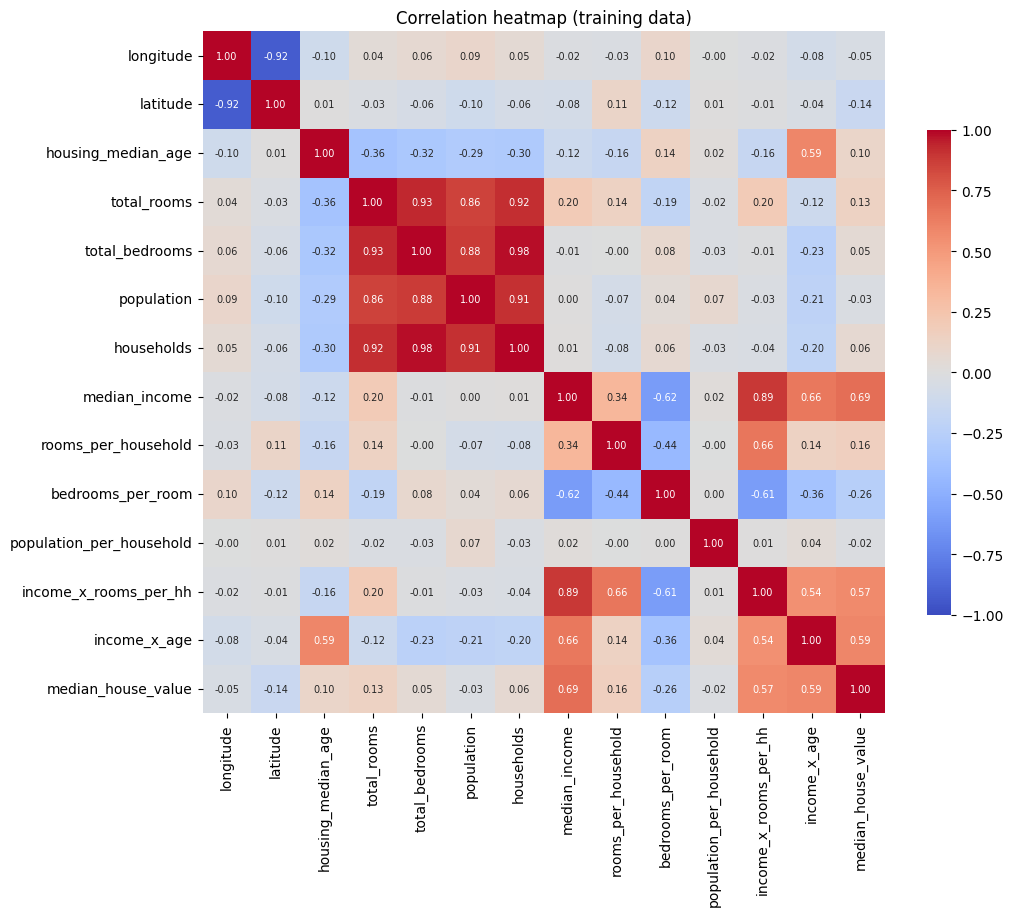

In [12]:
corr = train_df[full_features + [target]].corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.7}, annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation heatmap (training data)")
fig.savefig(f"{OUT}/01_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
def vif_table(frame, cols):
    """Variance inflation factor: 1 / (1 - R^2) from regressing each feature on the others."""
    X = frame[cols].copy()
    X = X.fillna(X.median())
    out = {}
    for c in cols:
        others = X.drop(columns=c)
        r2 = LinearRegression().fit(others, X[c]).score(others, X[c])
        out[c] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)

vif = pd.concat([vif_table(train_df, full_features).rename("VIF (full set)"),
                 vif_table(train_df, reduced_features).rename("VIF (reduced set)")],
                axis=1).round(1)
vif

,VIF (full set),VIF (reduced set)
total_bedrooms,51.0,NaN
households,47.1,NaN
median_income,21.1,20.1
total_rooms,19.6,NaN
income_x_rooms_per_hh,18.0,17.5
latitude,9.6,9.5
longitude,9.2,9.1
income_x_age,9.2,8.8
population,6.9,1.1
housing_median_age,5.5,5.3


**5. Preprocessing pipeline**

In [14]:
def make_pipeline(model, num_cols):
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num_cols),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_features)])
    return Pipeline([("prep", prep), ("model", model)])

def rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

**Does the feature set matter? (OLS, chosen by cross-validated RMSE)**

In [15]:
rows = []
for name, cols in [("Base 8 features", base_features),
                   ("Base + engineered (full)", full_features),
                   ("Drop collinear raw counts (reduced)", reduced_features)]:
    X_cols = cols + cat_features
    pipe = make_pipeline(LinearRegression(), cols)
    cv_rmse = -cross_val_score(pipe, train_df[X_cols], y_train, cv=cv,
                               scoring="neg_root_mean_squared_error").mean()
    pipe.fit(train_df[X_cols], y_train)
    pred = pipe.predict(test_df[X_cols])
    rows.append({"Feature set": name, "CV RMSE": round(cv_rmse),
                 "Test RMSE": round(rmse(y_test, pred)),
                 "Test R2": round(r2_score(y_test, pred), 4)})
pd.DataFrame(rows)

,Feature set,CV RMSE,Test RMSE,Test R2
0,Base 8 features,68604,70059,0.6254
1,Base + engineered (full),67675,68845,0.6383
2,Drop collinear raw counts (reduced),70324,71557,0.6092


**6. Tune Ridge and Lasso with GridSearchCV**

In [16]:
alphas = np.logspace(-3, 4, 29)
feat_cols = full_features + cat_features

searches = {}
for name, model in [("Ridge (L2)", Ridge()), ("Lasso (L1)", Lasso(max_iter=50000))]:
    gs = GridSearchCV(make_pipeline(model, full_features), {"model__alpha": alphas},
                      cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    gs.fit(train_df[feat_cols], y_train)
    searches[name] = gs
    print(f"{name}: best alpha = {gs.best_params_['model__alpha']:.4g}, "
          f"CV RMSE = {-gs.best_score_:,.0f}")

ols = make_pipeline(LinearRegression(), full_features).fit(train_df[feat_cols], y_train)
cv_ols = -cross_val_score(make_pipeline(LinearRegression(), full_features),
                          train_df[feat_cols], y_train, cv=cv,
                          scoring="neg_root_mean_squared_error").mean()
print(f"OLS: CV RMSE = {cv_ols:,.0f}")

Ridge (L2): best alpha = 31.62, CV RMSE = 67,659
Lasso (L1): best alpha = 100, CV RMSE = 67,661
OLS: CV RMSE = 67,675


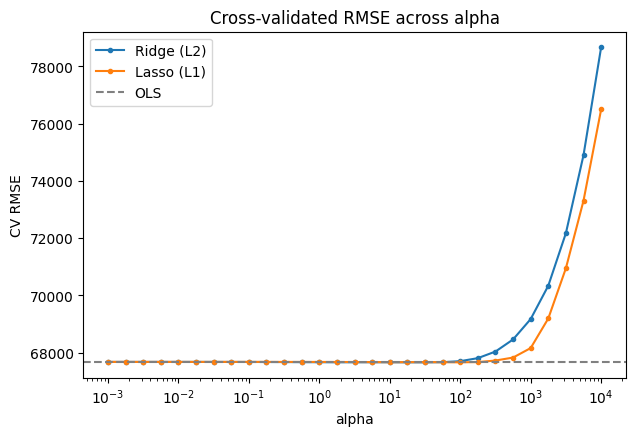

In [17]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, gs in searches.items():
    ax.plot(gs.cv_results_["param_model__alpha"].astype(float),
            -gs.cv_results_["mean_test_score"], marker="o", ms=3, label=name)
ax.axhline(cv_ols, color="gray", ls="--", label="OLS")
ax.set_xscale("log")
ax.set_xlabel("alpha"); ax.set_ylabel("CV RMSE")
ax.set_title("Cross-validated RMSE across alpha")
ax.legend()
fig.savefig(f"{OUT}/02_alpha_curves.png", dpi=150, bbox_inches="tight")
plt.show()

**7. Compare the three models on the held-out test set**

In [18]:
models = {"OLS": ols,
          "Ridge (L2)": searches["Ridge (L2)"].best_estimator_,
          "Lasso (L1)": searches["Lasso (L1)"].best_estimator_}
cv_scores = {"OLS": cv_ols,
             "Ridge (L2)": -searches["Ridge (L2)"].best_score_,
             "Lasso (L1)": -searches["Lasso (L1)"].best_score_}

rows, preds = [], {}
for name, m in models.items():
    p = m.predict(test_df[feat_cols])
    preds[name] = p
    coefs = m["model"].coef_
    alpha = getattr(m["model"], "alpha", np.nan)
    rows.append({"Model": name,
                 "Best alpha": round(alpha, 3) if alpha == alpha else "n/a",
                 "CV RMSE": round(cv_scores[name]),
                 "Test RMSE": round(rmse(y_test, p)),
                 "Test MAE": round(mean_absolute_error(y_test, p)),
                 "Test R2": round(r2_score(y_test, p), 4),
                 "Zero coefs": f"{int((coefs == 0).sum())} of {len(coefs)}"})
results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/results.csv", index=False)
results

,Model,Best alpha,CV RMSE,Test RMSE,Test MAE,Test R2,Zero coefs
0,OLS,n/a,67675,68845,49459,0.6383,0 of 17
1,Ridge (L2),31.623,67659,68935,49437,0.6374,0 of 17
2,Lasso (L1),100.0,67661,68937,49427,0.6373,1 of 17


In [19]:
names = list(models["OLS"]["prep"].get_feature_names_out())
names = [n.split("__", 1)[1] for n in names]
coef_table = pd.DataFrame({m: models[m]["model"].coef_ for m in models}, index=names).round(0)
coef_table = coef_table.reindex(coef_table["OLS"].abs().sort_values(ascending=False).index)
coef_table.to_csv(f"{OUT}/coefficients.csv")
coef_table

,OLS,Ridge (L2),Lasso (L1)
ocean_proximity_ISLAND,130943.0,14789.0,0.0
median_income,81270.0,78708.0,77948.0
latitude,-56767.0,-54089.0,-54666.0
longitude,-56392.0,-53808.0,-54114.0
population,-45428.0,-44403.0,-44203.0
households,37134.0,34472.0,36062.0
ocean_proximity_INLAND,-34398.0,-35938.0,-35382.0
bedrooms_per_room,18750.0,18266.0,18090.0
income_x_rooms_per_hh,-14483.0,-12115.0,-10794.0
rooms_per_household,13464.0,12142.0,11670.0


**8. Predicted vs actual**

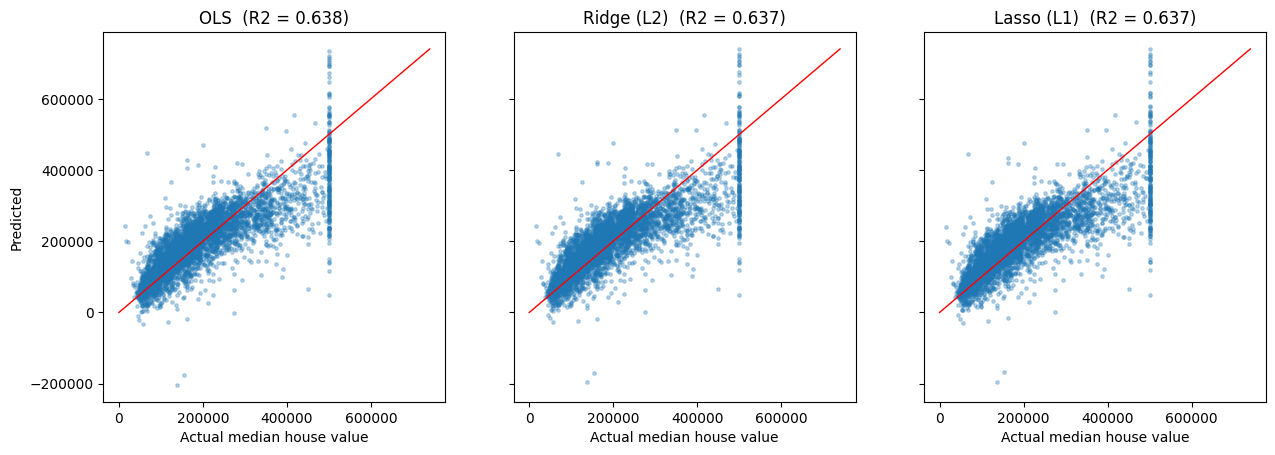

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharex=True, sharey=True)
lims = [0, max(y_test.max(), max(p.max() for p in preds.values()))]
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, s=6, alpha=0.3)
    ax.plot(lims, lims, color="red", lw=1)
    ax.set_title(f"{name}  (R2 = {r2_score(y_test, p):.3f})")
    ax.set_xlabel("Actual median house value")
axes[0].set_ylabel("Predicted")
fig.savefig(f"{OUT}/03_predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

**9. Residual distributions**

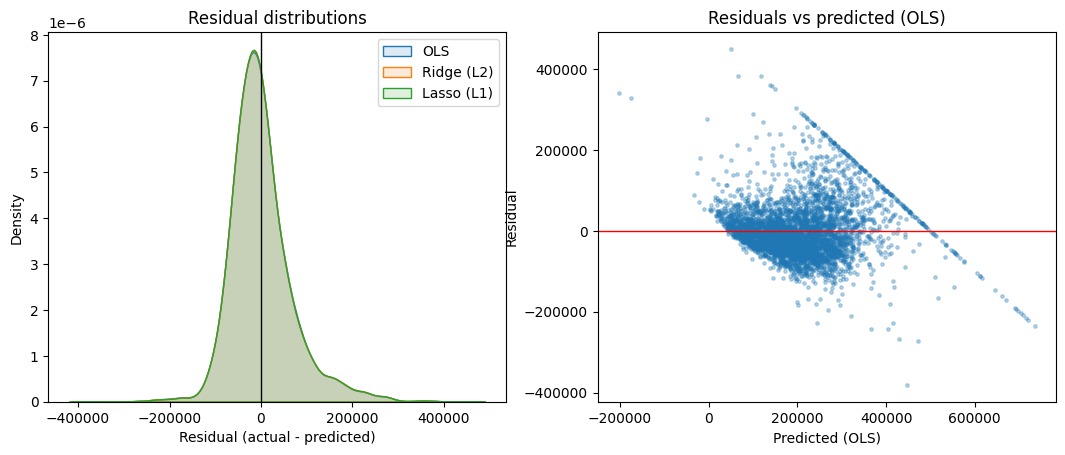

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name, p in preds.items():
    sns.kdeplot(y_test - p, ax=axes[0], label=name, fill=True, alpha=0.15)
axes[0].axvline(0, color="k", lw=1)
axes[0].set_xlabel("Residual (actual - predicted)")
axes[0].set_title("Residual distributions")
axes[0].legend()

axes[1].scatter(preds["OLS"], y_test - preds["OLS"], s=6, alpha=0.3)
axes[1].axhline(0, color="red", lw=1)
axes[1].set_xlabel("Predicted (OLS)"); axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs predicted (OLS)")
fig.savefig(f"{OUT}/04_residual_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

**How much does the capped target distort the scores?**

In [22]:
below = y_test < cap
check = pd.DataFrame({
    "Rows": [len(y_test), int(below.sum())],
    "OLS RMSE": [round(rmse(y_test, preds["OLS"])), round(rmse(y_test[below], preds["OLS"][below.values]))],
    "OLS R2": [round(r2_score(y_test, preds["OLS"]), 4), round(r2_score(y_test[below], preds["OLS"][below.values]), 4)]},
    index=["All test rows", "Rows below the cap"])
check

,Rows,OLS RMSE,OLS R2
All test rows,4128,68845,0.6383
Rows below the cap,3949,60850,0.6138


## 10. Results and interpretation

| Model | Best alpha | CV RMSE | Test RMSE | Test MAE | Test R² |
|---|---|---|---|---|---|
| OLS | n/a | 67,675 | 68,845 | 49,459 | 0.6383 |
| Ridge (L2) | 31.6 | 67,659 | 68,935 | 49,437 | 0.6374 |
| Lasso (L1) | 100 | 67,661 | 68,937 | 49,427 | 0.6373 |

**The three models perform the same.** Cross-validated RMSE differs by about $15 on a base near $67,700, and on the test set OLS is marginally the best of the three. Regularization buys no accuracy here, probably because there are 16,512 training rows for 17 features, so OLS has little variance to remove. I did not measure fold-to-fold variation, so I can't put a formal bound on that claim.

**Where regularization does something.** The `ISLAND` category has only 4 training rows. OLS gives it a coefficient of about 131,000 (standardized units), while Ridge shrinks it to about 15,000 and Lasso sets it to zero. That was the only coefficient Lasso removed (1 of 17). This is the one place where the penalty changes the fit, and it affects very few districts.

**Multicollinearity.** The raw count columns are heavily collinear (VIF about 51 for `total_bedrooms`, 47 for `households`, 20 for `total_rooms`). Interaction terms with `median_income` also push its VIF to about 21. Dropping the collinear raw counts made predictions worse (CV RMSE 70,324 vs 67,675), so I kept them and let Ridge and Lasso handle the collinearity. The price is that individual coefficients for correlated features are unreliable and should not be read causally. For example, `households` is positive while `population` is negative.

**Feature engineering helped modestly.** Adding the ratios and interactions lowered OLS cross-validated RMSE from 68,604 to 67,675 (about 1.4%).

**Limits of the models.**
- R² is about 0.64. A linear model cannot capture the nonlinear effect of location, and the predicted-vs-actual plot bends away from the diagonal at both ends.
- 965 of 20,640 districts have `median_house_value` capped at 500,001. They form the vertical column in the predicted-vs-actual plot and the diagonal line in the residual plot. On test rows below the cap, OLS RMSE is 60,850 against 68,845 on all rows, so the cap inflates the error.
- Some predictions are negative, which is impossible for a house value.
- Residuals are right-skewed and their spread grows with the predicted value, which breaks the constant-variance assumption behind OLS inference.
- The `ISLAND` category is too small (4 training rows, 1 test row) for any conclusion about it.


